In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
from pathlib import Path

from bioio import BioImage

# data_path = Path("/media/pandora/Greger_group/Xinyao/PRRT Revision/PRRTm750 A1rb647 PSDck555 RIMgp488/261007 Repeat/Experiment-152.czi")
channels = ["PRRT", "A1", "PSD", "RIM"]
data_path = Path(
    "/media/pandora/Greger_group/Xinyao/PRRT Revision/PRRTm750 A1rb647 PSDck555 RIMgp488/261020 Repeat/Experiment-358.czi"
)
image = BioImage(data_path)
data = image.xarray_dask_data.assign_coords({"C": channels})

In [4]:
import napari

v = napari.Viewer()
v.add_image(image.data, channel_axis=1, name=channels)

[<Image layer 'PRRT' at 0x7f1a2cee4590>,
 <Image layer 'A1' at 0x7f19f116ac10>,
 <Image layer 'PSD' at 0x7f19f1168550>,
 <Image layer 'RIM' at 0x7f19f116b110>]

# 2. Drift correction

In [5]:
from prrt_clustering import correct_z_drift

shift, stabilized = correct_z_drift(data)

In [ ]:
import matplotlib.pyplot as plt

plt.plot(shift.reset_index()["Z"], shift["DX [um]"])
plt.plot(shift.reset_index()["Z"], shift["DY [um]"])
plt.legend(["X", "Y"])
plt.xlabel("Z [um]")
plt.ylabel("shift [um]")

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

n = 500
a = data[0, 2, :, :n, :n].max(axis=1)
b = stabilized[0, 2, :, :n, :n].max(axis=1)
plt.subplot(311)
a.plot(add_colorbar=False, cmap="gray")
plt.subplot(312)
b.plot(add_colorbar=False, cmap="gray")
plt.subplot(313)
plt.imshow(np.stack([a, b, a], axis=2), aspect=4)
plt.suptitle("Z drift correction")
plt.tight_layout()


In [ ]:
# import napari
# v = napari.Viewer()
# v.add_image(image.data, channel_axis=1)
# v.add_image(stabilized.data[0,0,:,:100,:100], channel_axis=1)

## 2. Spot detection

- Detect spots in all channels

(<Figure size 2000x2000 with 4 Axes>,
 {'A1': <Axes: title={'center': 'A1'}>,
  'PRRT': <Axes: title={'center': 'PRRT'}>,
  'PSD': <Axes: title={'center': 'PSD'}>,
  'RIM': <Axes: title={'center': 'RIM'}>})

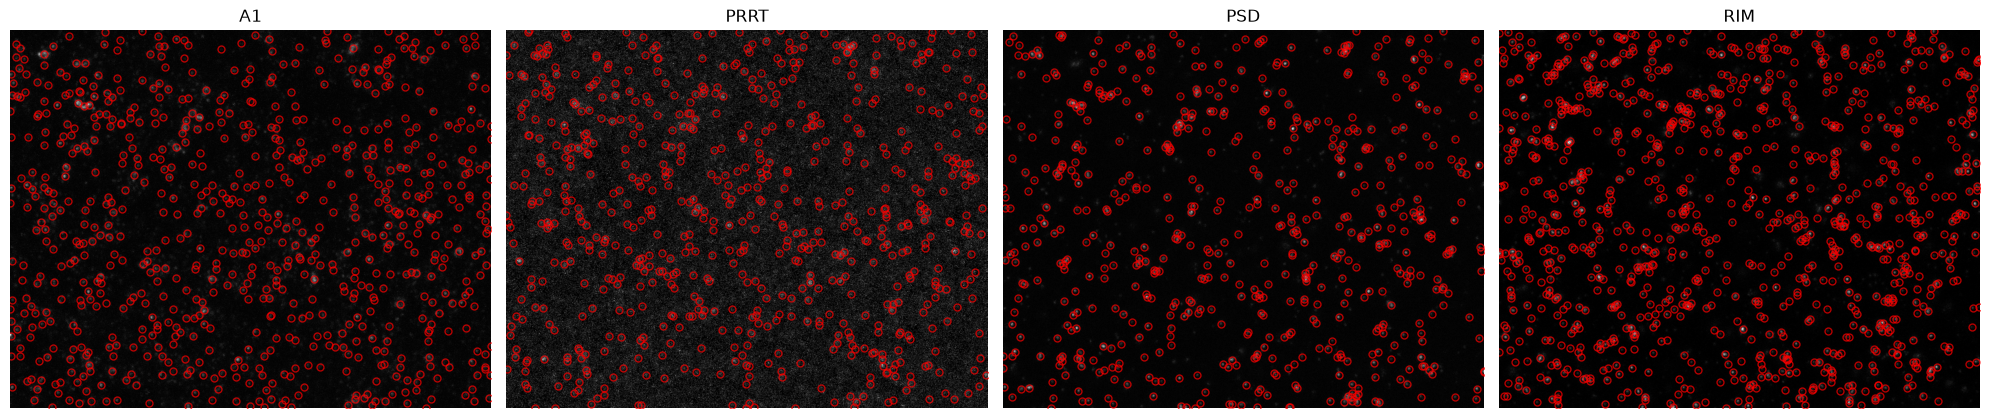

In [24]:
import matplotlib.pyplot as plt
import numpy as np

from prrt_clustering import detect_puncta, plot_data, plot_points

tmp = stabilized[0, :, :, 250:800, 800:1500]
parameters = {
    "PRRT": {"scale_um": 0.2, "specificity": 3},
    "A1": {"scale_um": 0.4, "specificity": 3},
    "PSD": {"scale_um": 0.1, "specificity": 8},
    "RIM": {"scale_um": 0.1, "specificity": 6},
}

points = detect_puncta(tmp, parameters)

fig = plt.figure(figsize=(20, 20))
fig, axes = plot_data(tmp, split=True, fig=fig)
plot_points(points, ms=10, split=True, axes_dict=axes)


In [ ]:
import napari

v = napari.Viewer(ndisplay=3)
# v.add_image(image.data, channel_axis=1)
vx = np.array([(tmp[a][1].values - tmp[a][0].values) for a in ["Z", "Y", "X"]])
o = np.array([tmp[a][0].values for a in ["Z", "Y", "X"]])
# v.add_image(tmp,scale=vx,translate=o, channel_axis=0,name=channels)
fcol = {"PRRT": "magenta", "A1": "red", "PSD": "green", "RIM": "yellow"}
for n, pts in points.groupby("C"):
    v.add_image(tmp.sel(C=n), scale=vx, translate=o, name=n, colormap=fcol[n])
    v.add_points(pts[["Z", "Y", "X"]], size=0.5, name=n, face_color=fcol[n])

## 3. Clustering
Cluster points to identify potential synapses.

In [ ]:
from prrt_clustering import clean_points_besag, cluster_dbscan, plot_clusters

clean = clean_points_besag(points[points["C"].isin(["PSD", "RIM"])], 2, 10, 1.1)
clean = clean[clean["noise"] == False]  # noqa: E712
cpoints, clusters = cluster_dbscan(clean, 1, 1)
cpoints = cpoints[cpoints["noise"] == False]
fig = plt.figure(figsize=(10, 10))
fig, axes = plot_data(tmp, split=True, fig=fig)
# plot_points(points,ms=5,split=True,axes=axes)
# plot_points(clean,ms=2,split=True,axes=axes)
plot_clusters(cpoints, ms=10, split=True, axes=axes)

Channel PSD cluster:578, points:42
Channel RIM cluster:947, points:102
Number of synpases 14


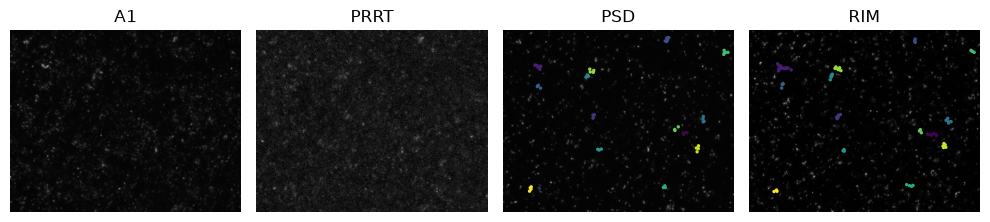

In [90]:
from prrt_clustering import  find_synapses, plot_clusters
import pandas as pd

spoints, clusters, synapses = find_synapses(points, eps=1.5, min_samples=3, distance=1.)
# points = spoints[spoints["noise"]==False]
fig = plt.figure(figsize=(10, 10))
fig, axes = plot_data(tmp, split=True, fig=fig)
# fig, axes = plot_points(clusters, split=True, axes_dict=axes)
# plot_points(spoints, ms=1, split=True, axes_dict=axes)
x = spoints[(spoints["synapse"]>=0)&(spoints["C"]=="RIM")]
axes["RIM"].scatter(x['X'],x['Y'],c=x['synapse'],s=2)
x = spoints[(spoints["synapse"]>=0)&(spoints["C"]=="PSD")]
axes["PSD"].scatter(x['X'],x['Y'],c=x['synapse'],s=2)


In [71]:
from prrt_clustering.clustering import quantification

df = quantification(spoints, 0.5)

In [ ]:
# PRRT1 at GluA1-containing synapse
num_synapses = len(df)
num_a1_synapses = (df["A1"] > 0).sum()
num_a1_prrt_synapses = ((df["PRRT"] > 0) & ( df["A1"] > 0)).sum()
{
    "Number of synpases": num_synapses,
    "Number of GluA1-containing synapse":num_a1_synapses,
    "Fraction of PRRT1 at GluA1-containing synapse":float(100*num_a1_prrt_synapses/num_a1_synapses),
 }


SyntaxError: closing parenthesis '}' does not match opening parenthesis '(' on line 5 (578946634.py, line 7)